In [ ]:
!pip install  pmdarima

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 688.9/688.9 kB 11.7 MB/s eta 0:00:00


In [ ]:
import os
import pandas as pd
from google.colab import drive

# 1. Mount Google Drive
drive.mount("/content/drive")

# 2. Define dataset paths
drive_path = (
    "/content/drive/MyDrive/Research Papers/Dataset/"
    "Voluntary-Registry-Offsets-Database--v2026-06-PROJECTS.csv"
)
local_path = "/content/dataset_local.csv"

# 3. Locate the dataset
if os.path.isfile(drive_path):
    dataset_path = drive_path
elif os.path.isfile(local_path):
    dataset_path = local_path
else:
    raise FileNotFoundError(
        "Dataset not found. Please verify the Google Drive path "
        "or upload the dataset to /content/dataset_local.csv."
    )

print(f"Loading dataset from: {dataset_path}")

# 4. Load the dataset
df_projects = pd.read_csv(
    dataset_path,
    skiprows=3,
    low_memory=False
)

# 5. Validate the required column
if "Country" not in df_projects.columns:
    raise KeyError(
        f"'Country' column not found. Available columns: "
        f"{df_projects.columns.tolist()}"
    )

# 6. Filter projects located in India
df_india = (
    df_projects.loc[
        df_projects["Country"]
        .astype("string")
        .str.strip()
        .str.casefold()
        .eq("india")
    ]
    .copy()
    .reset_index(drop=True)
)

# 7. Display results
print(f"\nTotal projects in dataset: {len(df_projects):,}")
print(f"Projects in India: {len(df_india):,}")

display(df_india.head())

### 2. Time Series Data Preparation
I will now process the filtered data to create a yearly time series of credits issued.

In [ ]:
import os
import pandas as pd

# Fallback check: If df_india is not defined, load and recreate it
if 'df_india' not in globals():
    print("'df_india' not found in memory. Re-loading dataset to recover state...")
    drive_path = "/content/drive/MyDrive/Research Papers/Dataset/Voluntary-Registry-Offsets-Database--v2026-06-PROJECTS.csv"
    local_path = "/content/dataset_local.csv"
    direct_path = "/content/Voluntary-Registry-Offsets-Database--v2026-06-PROJECTS.csv"

    if os.path.isfile(drive_path):
        dataset_path = drive_path
    elif os.path.isfile(local_path):
        dataset_path = local_path
    elif os.path.isfile(direct_path):
        dataset_path = direct_path
    else:
        raise FileNotFoundError(
            "Dataset not found. Please run the setup cells first or verify your dataset paths."
        )

    df_projects = pd.read_csv(dataset_path, skiprows=3, low_memory=False)
    df_india = df_projects.loc[
        df_projects["Country"].astype(str).str.strip().str.casefold().eq("india")
    ].copy().reset_index(drop=True)

# Clean column names to handle newlines and extra spaces
df_india.columns = df_india.columns.str.replace('\n', ' ', regex=True).str.strip()

# Print cleaned columns to verify
print("Cleaned columns found:", df_india.columns.tolist())

# Find the correct column names using flexible substring matching to handle double spaces
target_col = [c for c in df_india.columns if 'Total Credits' in c and 'Issued' in c][0]
date_col = [c for c in df_india.columns if 'First Year of Project' in c][0]

print(f"Using target column: {target_col}")
print(f"Using date column: {date_col}")

# Convert to numeric
df_india[target_col] = df_india[target_col].astype(str).str.replace(',', '', regex=False)
df_india[target_col] = pd.to_numeric(df_india[target_col], errors='coerce').fillna(0)

# Aggregate by year
time_series = df_india.groupby(date_col)[target_col].sum().reset_index()

# Filter out years with 0 credits and ensure the year is an integer for conversion
time_series = time_series[time_series[target_col] > 0]
time_series = time_series[pd.to_numeric(time_series[date_col], errors='coerce').notnull()]

# Set index and convert to DatetimeIndex (start of year)
time_series[date_col] = pd.to_datetime(time_series[date_col].astype(int), format='%Y')
time_series = time_series.set_index(date_col).sort_index()

# Standardize column name for subsequent cells
time_series.columns = ['Total Credits Issued']

display(time_series.head())
display(time_series.tail())

'df_india' not found in memory. Re-loading dataset to recover state...
Cleaned columns found: ['Project ID', 'Project Name', 'Voluntary Registry', 'ARB / WA  Project', 'Voluntary Status', 'Scope', 'Type', 'Reduction / Removal', 'Methodology / Protocol', 'Methodology Version', 'Region', 'Country', 'State', 'Project Site Location', 'Project Developer', 'Total Credits  Issued', 'Total Credits  Retired', 'Total Credits Remaining', 'Total Buffer  Pool Deposits', 'Reversals Covered by Buffer Pool', 'Reversals Not Covered by Buffer', 'Buffer Credits Released to Project', 'First Year of Project (Vintage)', '1996', '1997', '1998', '1999', '2000', '2001', '2002', '2003', '2004', '2005', '2006', '2007', '2008', '2009', '2010', '2011', '2012', '2013', '2014', '2015', '2016', '2017', '2018', '2019', '2020', '2021', '2022', '2023', '2024', '2025', '2026', '1996.1', '1997.1', '1998.1', '1999.1', '2000.1', '2001.1', '2002.1', '2003.1', '2004.1', '2005.1', '2006.1', '2007.1', '2008.1', '2009.1', '2010.

,Total Credits Issued
First Year of Project (Vintage),
2001-01-01,4760721
2004-01-01,174424
2005-01-01,2287316
2006-01-01,29296206
2007-01-01,28693083


,Total Credits Issued
First Year of Project (Vintage),
2022-01-01,12805284
2023-01-01,2929859
2024-01-01,75699
2025-01-01,9868
2026-01-01,10


### 3. Time Series Visualization

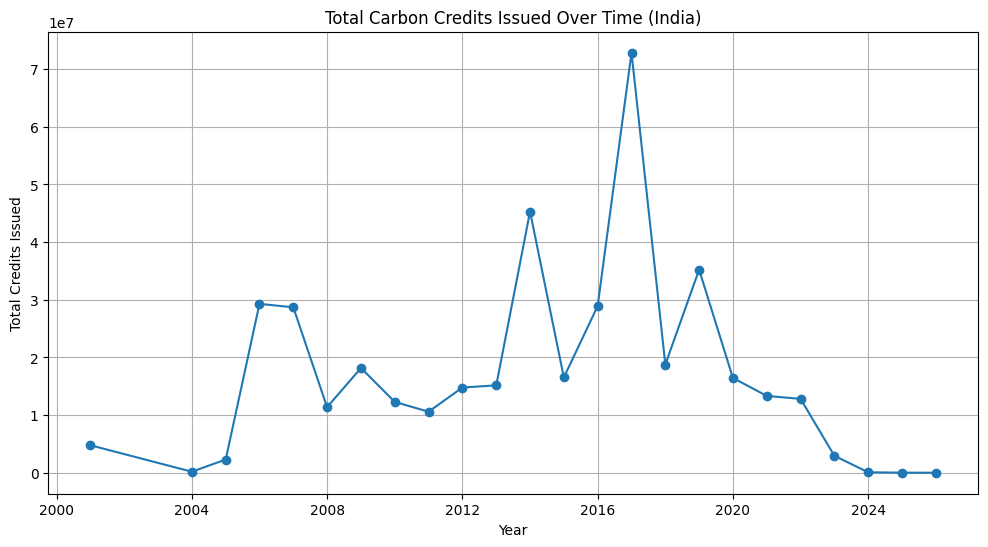

In [ ]:
plt.figure(figsize=(12, 6))
plt.plot(time_series.index, time_series['Total Credits Issued'], marker='o')
plt.title('Total Carbon Credits Issued Over Time (India)')
plt.xlabel('Year')
plt.ylabel('Total Credits Issued')
plt.grid(True)
plt.show()

### Exploring the Post-2016 Dip
We will analyze the composition of Indian projects by 'Type' and 'Voluntary Status' around the 2016-2018 peak to see what changed.

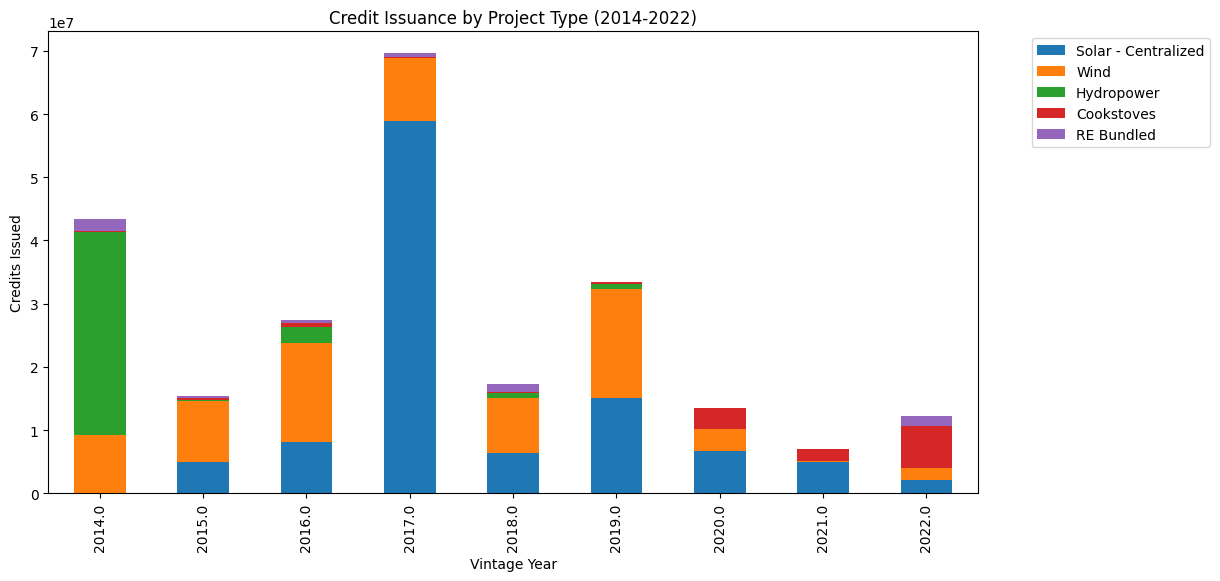

Voluntary Status,Crediting Period Renewal Requested,Crediting Period Renewal and Verification Approval Requested,Gold Standard Certified Project,Late to verify,On Hold - see notification letter,Registered,Verification approval requested,Withdrawn
First Year of Project (Vintage),,,,,,,,
2014.0,0.0,2829720.0,4149662.0,92164.0,0.0,37934171.0,293574.0,0.0
2015.0,0.0,0.0,5328112.0,90641.0,0.0,8906569.0,2108294.0,99931.0
2016.0,6189328.0,0.0,5021014.0,2478805.0,0.0,6782775.0,8430575.0,0.0
2017.0,0.0,0.0,9580562.0,367966.0,0.0,57935733.0,4925287.0,46473.0
2018.0,0.0,0.0,3828545.0,54223.0,684620.0,9901231.0,4297410.0,0.0
2019.0,0.0,0.0,27700042.0,0.0,275987.0,5077178.0,2166380.0,0.0
2020.0,0.0,0.0,15362923.0,0.0,35820.0,1030924.0,7999.0,0.0
2021.0,0.0,0.0,7629503.0,0.0,0.0,3308367.0,612210.0,1778394.0
2022.0,0.0,0.0,8041621.0,0.0,0.0,3386240.0,1377423.0,0.0


In [ ]:
# Analyze top project types contributing to the peak and subsequent dip
df_india_recent = df_india[df_india[date_col].astype(float).between(2014, 2022)].copy()

# Pivot data to see 'Total Credits Issued' by Year and Project Type
dip_analysis = df_india_recent.pivot_table(
    index=date_col,
    columns='Type',
    values=target_col,
    aggfunc='sum'
).fillna(0)

# Plot the top 5 contributing types
top_types = dip_analysis.sum().nlargest(5).index
dip_analysis[top_types].plot(kind='bar', stacked=True, figsize=(12, 6))
plt.title('Credit Issuance by Project Type (2014-2022)')
plt.ylabel('Credits Issued')
plt.xlabel('Vintage Year')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()

# Check for status changes (e.g., projects becoming 'Inactive' or 'Completed')
status_breakdown = df_india_recent.groupby([date_col, 'Voluntary Status'])[target_col].sum().unstack().fillna(0)
display(status_breakdown)

### 4. ARIMA Model Training and Forecasting

In [ ]:
# Ensure continuous annual frequency using 'YS' (Year Start) frequency
full_date_range = pd.date_range(
    start=time_series.index.min(),
    end=time_series.index.max(),
    freq='YS'
)
time_series = time_series.reindex(full_date_range, fill_value=0).asfreq('YS')

# Split data: last 4 years for testing
test_periods = 4
train = time_series.iloc[:-test_periods]
test = time_series.iloc[-test_periods:]

# Explicitly ensure the frequency is set on the indices
train.index.freq = 'YS'
test.index.freq = 'YS'

# Auto ARIMA
model = pm.auto_arima(train['Total Credits Issued'],
                      seasonal=False,
                      trace=True,
                      error_action='ignore',
                      suppress_warnings=True)

print(model.summary())

# Forecast
forecast, conf_int = model.predict(n_periods=test_periods, return_conf_int=True)

### 5. Forecast Evaluation and Visualization

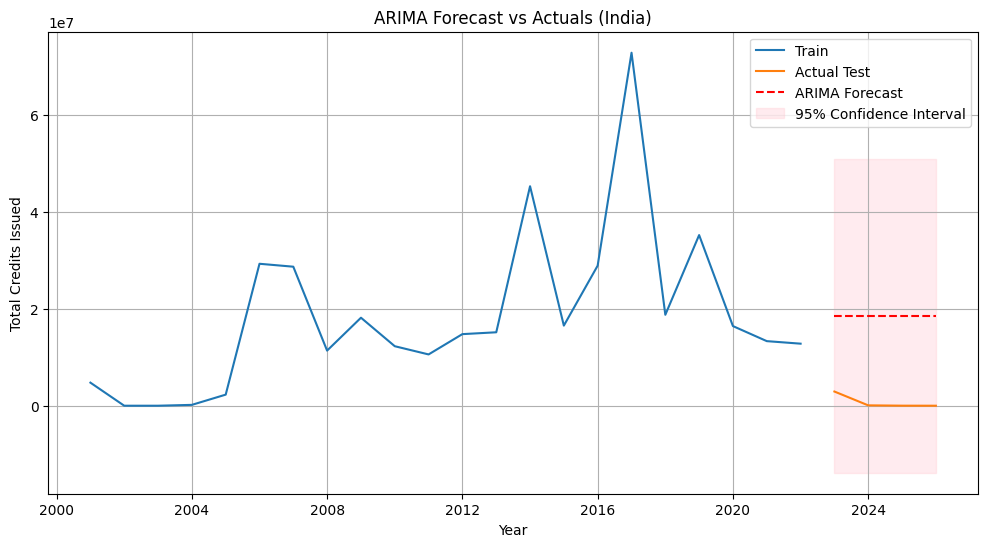

Test RMSE: 17,822,132.20


In [ ]:
import numpy as np
from sklearn.metrics import mean_squared_error
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
plt.plot(train.index, train['Total Credits Issued'], label='Train')
plt.plot(test.index, test['Total Credits Issued'], label='Actual Test')
plt.plot(test.index, forecast, label='ARIMA Forecast', color='red', linestyle='--')
plt.fill_between(test.index, conf_int[:, 0], conf_int[:, 1], color='pink', alpha=0.3, label='95% Confidence Interval')
plt.legend()
plt.title('ARIMA Forecast vs Actuals (India)')
plt.xlabel('Year')
plt.ylabel('Total Credits Issued')
plt.grid(True)
plt.show()

rmse = np.sqrt(mean_squared_error(test['Total Credits Issued'], forecast))
print(f'Test RMSE: {rmse:,.2f}')

### 6. Discussion and Comparison

**ARIMA vs. Regression (XGBoost):**
- **ARIMA** is specialized for capturing internal temporal structures (autocorrelation). It is best when the primary driver is historical trend and data is univariate.
- **XGBoost/Regression** is superior when external drivers (GDP, policy changes, sector-specific data) are available as features. However, regression models often ignore the chronological sequence unless lag features are manually engineered.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
import pmdarima as pm
from sklearn.metrics import mean_squared_error
import numpy as np

In [ ]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.backends.backend_pdf import PdfPages
from sklearn.metrics import mean_squared_error, mean_absolute_error
from statsmodels.tsa.stattools import adfuller
import numpy as np

# Try pmdarima first; fall back to statsmodels if it's not importable
try:
    import pmdarima as pm
    HAS_PMDARIMA = True
except ImportError:
    from statsmodels.tsa.arima.model import ARIMA
    HAS_PMDARIMA = False
    print("pmdarima unavailable — falling back to statsmodels ARIMA(3,0,0)")

# Mount Drive if not already mounted (safe to call even if already mounted)
try:
    from google.colab import drive
    drive.mount('/content/drive')
except Exception as e:
    print(f"Drive mount skipped or already mounted: {e}")

# ---------------------------------------------------------------------------
# Output PDF path
# ---------------------------------------------------------------------------
PDF_PATH = '/content/carbon_credits_arima_report.pdf'


def add_text_page(pdf, text, title=None, fontsize=10):
    """Helper to render plain text as a PDF page."""
    fig = plt.figure(figsize=(12, 6))
    plt.axis('off')
    if title:
        plt.title(title, fontsize=14, loc='left')
    plt.text(0, 1, text, fontsize=fontsize, va='top', ha='left', family='monospace', wrap=True)
    pdf.savefig(fig, dpi=200, bbox_inches='tight')
    plt.close(fig)


with PdfPages(PDF_PATH) as pdf:

    # -----------------------------------------------------------------------
    # 1. Data Loading and Filtering
    # -----------------------------------------------------------------------
    file_path = '/content/drive/MyDrive/Research Papers/Dataset/Voluntary-Registry-Offsets-Database--v2026-06-PROJECTS.csv'

    if not os.path.exists(file_path):
        raise FileNotFoundError(
            f"CSV not found at: {file_path}\n"
            f"Check that Drive is mounted and the filename/path is exact "
            f"(right-click the file in the sidebar to confirm)."
        )

    df_projects = pd.read_csv(file_path, skiprows=3)

    # Filter for India projects
    df_india = df_projects[df_projects['Country'] == 'India'].copy()

    # -------------------------------------------------------------------
    # 2. Time Series Data Preparation
    # -------------------------------------------------------------------
    df_india.columns = df_india.columns.str.replace('\n', ' ', regex=True).str.strip()

    cols_text = "Cleaned columns found:\n" + "\n".join(df_india.columns.tolist())
    print(cols_text)

    target_col = [c for c in df_india.columns if 'Total Credits' in c and 'Issued' in c][0]
    date_col = [c for c in df_india.columns if 'First Year of Project' in c][0]

    info_text = f"Using target column: {target_col}\nUsing date column: {date_col}"
    print(info_text)
    add_text_page(pdf, cols_text + "\n\n" + info_text, title="Data Columns")

    # Convert to numeric
    df_india[target_col] = df_india[target_col].astype(str).str.replace(',', '', regex=False)
    df_india[target_col] = pd.to_numeric(df_india[target_col], errors='coerce').fillna(0)

    # Aggregate by year
    time_series = df_india.groupby(date_col)[target_col].sum().reset_index()

    # Filter out years with 0 credits and ensure the year is an integer
    time_series = time_series[time_series[target_col] > 0]
    time_series = time_series[pd.to_numeric(time_series[date_col], errors='coerce').notnull()]

    # Set index and convert to DatetimeIndex (start of year)
    time_series[date_col] = pd.to_datetime(time_series[date_col].astype(int), format='%Y')
    time_series = time_series.set_index(date_col).sort_index()
    time_series.columns = ['Total Credits Issued']

    add_text_page(
        pdf,
        "Head:\n" + time_series.head().to_string() + "\n\nTail:\n" + time_series.tail().to_string(),
        title="Time Series Preview"
    )

    # -------------------------------------------------------------------
    # 3. Time Series Visualization
    # -------------------------------------------------------------------
    fig = plt.figure(figsize=(12, 6))
    plt.plot(time_series.index, time_series['Total Credits Issued'], marker='o')
    plt.title('Total Carbon Credits Issued Over Time (India)')
    plt.xlabel('Year')
    plt.ylabel('Total Credits Issued')
    plt.grid(True)
    pdf.savefig(fig, dpi=200, bbox_inches='tight')
    plt.close(fig)

    # -------------------------------------------------------------------
    # Exploring the Post-2016 Dip
    # -------------------------------------------------------------------
    df_india_recent = df_india[df_india[date_col].astype(float).between(2014, 2022)].copy()

    if df_india_recent.empty:
        add_text_page(pdf, "No India project data available for 2014-2022.",
                      title="Credit Issuance by Type (2014-2022)")
        add_text_page(pdf, "No India project data available for 2014-2022.",
                      title="Status Breakdown (2014-2022)")
    else:
        dip_analysis = df_india_recent.pivot_table(
            index=date_col,
            columns='Type',
            values=target_col,
            aggfunc='sum'
        ).fillna(0)

        if dip_analysis.empty:
            add_text_page(pdf, "No project-type breakdown available for 2014-2022.",
                          title="Credit Issuance by Type (2014-2022)")
        else:
            top_types = dip_analysis.sum().nlargest(5).index
            ax = dip_analysis[top_types].plot(kind='bar', stacked=True, figsize=(12, 6))
            plt.title('Credit Issuance by Project Type (2014-2022)')
            plt.ylabel('Credits Issued')
            plt.xlabel('Vintage Year')
            plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
            fig = ax.get_figure()
            pdf.savefig(fig, dpi=200, bbox_inches='tight')
            plt.close(fig)

        # Check for status changes (e.g., projects becoming 'Inactive' or 'Completed')
        status_breakdown = df_india_recent.groupby(
            [date_col, 'Voluntary Status']
        )[target_col].sum().unstack().fillna(0)
        add_text_page(pdf, status_breakdown.to_string(), title="Status Breakdown (2014-2022)")

    # -------------------------------------------------------------------
    # 4. Stationarity Check (ADF Test) — run before modeling
    # -------------------------------------------------------------------
    test_periods = 4
    train = time_series.iloc[:-test_periods]
    test = time_series.iloc[-test_periods:]

    try:
        adf_result = adfuller(train['Total Credits Issued'])
        adf_text = (
            f"ADF Statistic: {adf_result[0]:.4f}\n"
            f"p-value: {adf_result[1]:.4f}\n"
        )
        if adf_result[1] < 0.05:
            adf_text += "Result: Series appears STATIONARY (reject H0 at 5%)."
        else:
            adf_text += "Result: Series appears NON-STATIONARY (fail to reject H0 at 5%). Consider differencing (d>0)."
    except Exception as e:
        adf_text = f"ADF test could not be run: {e}"

    print(adf_text)
    add_text_page(pdf, adf_text, title="Stationarity Check (ADF Test)")

    # -------------------------------------------------------------------
    # 5. ARIMA Model Training and Forecasting
    # -------------------------------------------------------------------
    if HAS_PMDARIMA:
        model = pm.auto_arima(train['Total Credits Issued'],
                              seasonal=False,
                              trace=True,
                              error_action='ignore',
                              suppress_warnings=True)

        add_text_page(pdf, str(model.summary()), title="Auto ARIMA Model Summary", fontsize=8)

        # Explicit coefficient significance reporting
        try:
            params = model.params()
            pvalues = model.pvalues()
            names = params.index if hasattr(params, 'index') else [f"param_{i}" for i in range(len(pvalues))]
            sig_text = "Parameter significance (p<0.05 = significant):\n"
            for name, p in zip(names, pvalues):
                flag = "SIGNIFICANT" if p < 0.05 else "not significant"
                sig_text += f"  {name}: p={p:.3f}  ({flag})\n"
        except Exception as e:
            sig_text = f"Could not extract parameter significance: {e}"
        print(sig_text)
        add_text_page(pdf, sig_text, title="Coefficient Significance")

        forecast, conf_int = model.predict(n_periods=test_periods, return_conf_int=True)

    else:
        # Fallback: fixed ARIMA(3,0,0) via statsmodels
        sm_model = ARIMA(train['Total Credits Issued'], order=(3, 0, 0)).fit()
        add_text_page(pdf, str(sm_model.summary()), title="ARIMA(3,0,0) Model Summary (statsmodels)", fontsize=8)

        pvalues = sm_model.pvalues
        sig_text = "Parameter significance (p<0.05 = significant):\n"
        for name, p in pvalues.items():
            flag = "SIGNIFICANT" if p < 0.05 else "not significant"
            sig_text += f"  {name}: p={p:.3f}  ({flag})\n"
        print(sig_text)
        add_text_page(pdf, sig_text, title="Coefficient Significance")

        fc_res = sm_model.get_forecast(steps=test_periods)
        forecast = fc_res.predicted_mean.values
        ci_df = fc_res.conf_int(alpha=0.05)
        conf_int = ci_df.values

    # -------------------------------------------------------------------
    # 6. Forecast Evaluation and Visualization
    # -------------------------------------------------------------------
    fig = plt.figure(figsize=(12, 6))
    plt.plot(train.index, train['Total Credits Issued'], label='Train')
    plt.plot(test.index, test['Total Credits Issued'], label='Actual Test')
    plt.plot(test.index, forecast, label='ARIMA Forecast', color='red')
    plt.fill_between(test.index, conf_int[:, 0], conf_int[:, 1], color='pink', alpha=0.3)
    plt.legend()
    plt.title('ARIMA Forecast vs Actuals')
    pdf.savefig(fig, dpi=200, bbox_inches='tight')
    plt.close(fig)

    rmse = np.sqrt(mean_squared_error(test['Total Credits Issued'], forecast))
    mae = mean_absolute_error(test['Total Credits Issued'], forecast)
    mean_actual = test['Total Credits Issued'].mean()

    metrics_text = (
        f"Test RMSE: {rmse:,.2f}\n"
        f"Test MAE:  {mae:,.2f}\n"
        f"Mean actual (test period): {mean_actual:,.2f}\n"
    )
    if mean_actual > 0:
        metrics_text += f"RMSE as % of mean actual: {100 * rmse / mean_actual:.1f}%\n"
        metrics_text += "(A large % here means the error is comparable to or larger than\n" \
                         " the typical test-period value — treat forecast with caution.)"
    else:
        metrics_text += "Mean actual is zero or near-zero — RMSE/MAE should be interpreted\n" \
                         "with caution, as relative error is undefined."

    print(metrics_text)
    add_text_page(pdf, metrics_text, title="Forecast Evaluation")

    # -------------------------------------------------------------------
    # 7. Discussion and Comparison
    # -------------------------------------------------------------------
    discussion = """ARIMA vs. Regression (XGBoost):
- ARIMA is specialized for capturing internal temporal structures (autocorrelation).
  It is best when the primary driver is historical trend and data is univariate.
- XGBoost/Regression is superior when external drivers (GDP, policy changes,
  sector-specific data) are available as features. However, regression models
  often ignore the chronological sequence unless lag features are manually
  engineered.

Caveats for this analysis:
- Check the "Coefficient Significance" and "Stationarity Check" pages above:
  insignificant AR coefficients or a non-stationary series both suggest the
  ARIMA fit should be treated as indicative, not conclusive.
- If test-period actuals are near zero, RMSE can look large in absolute terms
  even when the model captures the general trend — see the RMSE-as-%-of-mean
  metric for context."""
    add_text_page(pdf, discussion, title="Discussion and Comparison")

print(f"PDF report saved to {PDF_PATH}")

# Download the PDF in Colab
try:
    from google.colab import files
    files.download(PDF_PATH)
except Exception as e:
    print(f"Could not trigger browser download (not running in Colab?): {e}")

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import pmdarima as pm
from google.colab import drive
from sklearn.metrics import mean_squared_error
import numpy as np # Import numpy for np.sqrt

# 1. Mount Google Drive
drive.mount('/content/drive')

# 2. Specify Google Drive path and load dataset
drive_path2 = '/content/drive/MyDrive/Research Papers/Dataset/Voluntary-Registry-Offsets-Database--v2026-06-PROJECTS.csv'
df = pd.read_csv(drive_path2, skiprows=3, low_memory=False)

# 3. Filter for India
df_india = df[df['Country'] == 'India'].copy()

# Clean headers and dynamically identify target/time columns
df_india.columns = df_india.columns.str.replace('\n', ' ', regex=True).str.strip()

target_col = [
    col for col in df_india.columns if 'Total Credits' in col and 'Issued' in col
][0]
time_col = [
    col for col in df_india.columns if 'First Year of Project' in col
][0]

# Clean numeric values
df_india[target_col] = (
    df_india[target_col].astype(str).str.replace(',', '')
)
df_india[target_col] = pd.to_numeric(
    df_india[target_col], errors='coerce'
).fillna(0)

# Build time series DataFrame
ts_data = df_india.groupby(time_col)[target_col].sum().reset_index()
ts_data = ts_data[(ts_data[target_col] > 0) & (ts_data[time_col].notna())]
ts_data[time_col] = pd.to_datetime(
    ts_data[time_col].astype(int).astype(str), format='%Y'
)
ts_data.set_index(time_col, inplace=True)

# Ensure continuous annual frequency using updated 'YS' (Year Start) frequency
full_date_range = pd.date_range(
    start=ts_data.index.min(),
    end=ts_data.index.max(),
    freq='YS'
)
ts_data = ts_data.reindex(full_date_range, fill_value=0).asfreq('YS')

# Scale target column to Millions for numerical stability
ts_data[target_col] = ts_data[target_col] / 1e6

# 4. Split data into training (80%) and testing (20%) sets
train_size = int(len(ts_data) * 0.8)
train, test = ts_data.iloc[:train_size], ts_data.iloc[train_size:]

# Explicitly ensure the frequency is set on the indices of train and test
# This is sometimes necessary as slicing can drop frequency information for statsmodels
train.index.freq = 'YS'
test.index.freq = 'YS'

# 5. Train Auto-ARIMA model
model = pm.auto_arima(
    train[target_col],
    seasonal=False,
    stepwise=True,
    suppress_warnings=True,
    error_action='ignore',
    trace=True
)

# 6. Model Summary and Predictions
print('\n--- Model Summary ---')
print(model.summary())

predictions = model.predict(n_periods=len(test))

# 7. Evaluate Performance
mse = mean_squared_error(test[target_col], predictions)
rmse = np.sqrt(mse) # Calculate RMSE by taking the square root of MSE

print(f'\nMean Squared Error (MSE): {mse:.4f} (Million Credits²)')
print(f'Root Mean Squared Error (RMSE): {rmse:.4f} Million Credits')

# 8. Visualization: Actual vs Predicted
plt.figure(figsize=(12, 6))
plt.plot(train.index, train[target_col], label='Train Data', marker='o', color='blue')
plt.plot(test.index, test[target_col], label='Test Data (Actual)', marker='o', color='green')
plt.plot(test.index, predictions, label='Predicted Forecast', marker='x', linestyle='--', color='red')

plt.title('India Voluntary Carbon Credits: Train vs Test Predictions')
plt.xlabel('Year')
plt.ylabel('Total Credits Issued (in Millions)')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
from sklearn.metrics import r2_score

# Calculate R-squared on the test set
r2 = r2_score(test[target_col], predictions)
print(f"R-squared (R²) Score: {r2:.4f}")

In [ ]:
import pandas as pd
import requests
import io

# Add any FRED commodity ID here to include it in your 15+ year dataset
urls = {
    'Brent_Crude_USD': 'https://fred.stlouisfed.org/graph/fredgraph.csv?id=POILBREUSDM',
    'Coal_USD':        'https://fred.stlouisfed.org/graph/fredgraph.csv?id=PCOALAUUSDM',
    'Gold_USD':        'https://fred.stlouisfed.org/graph/fredgraph.csv?id=GOLDAMGBD228NLBM',
    'NatGas_USD':      'https://fred.stlouisfed.org/graph/fredgraph.csv?id=PNGASUSDM',
    'USD_INR':          'https://fred.stlouisfed.org/graph/fredgraph.csv?id=EXINUS'
}

headers = {'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64)'}

dfs = []
for name, url in urls.items():
    response = requests.get(url, headers=headers)
    df = pd.read_csv(io.StringIO(response.text))

    date_col = df.columns[0]
    value_col = df.columns[1]

    df['Date'] = pd.to_datetime(df[date_col], errors='coerce')
    df[name] = pd.to_numeric(df[value_col], errors='coerce')

    df = df[['Date', name]].dropna().set_index('Date')
    dfs.append(df)

# Combine all commodities into one table from 2005 onwards
df_15yr = pd.concat(dfs, axis=1).dropna()
df_15yr = df_15yr[df_15yr.index >= '2005-01-01']

# Convert all USD values to INR dynamically
for col in ['Brent_Crude_USD', 'Coal_USD', 'Gold_USD', 'NatGas_USD']:
    inr_col_name = col.replace('_USD', '_INR')
    df_15yr[inr_col_name] = df_15yr[col] * df_15yr['USD_INR']

df_15yr.to_csv('multi_commodity_15year_INR.csv')
print(df_15yr.head())

ConnectionError: ('Connection aborted.', ConnectionResetError(104, 'Connection reset by peer'))

In [ ]:
import io
import os
import shutil
import warnings
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Suppress openpyxl workbook style warnings
warnings.filterwarnings('ignore', category=UserWarning, module='openpyxl')

# ---------------------------------------------------------
# 1. File Paths Configuration
# ---------------------------------------------------------
base_dir = '/content/drive/MyDrive/Research Papers'

if 'drive_path2' not in globals():
    drive_path2 = os.path.join(base_dir, 'Dataset/Voluntary-Registry-Offsets-Database--v2026-06-PROJECTS.csv')

cmo_excel_path = os.path.join(base_dir, 'CMO-Historical-Data-Annual.xlsx')
if not os.path.exists(cmo_excel_path):
    cmo_excel_path = '/content/CMO-Historical-Data-Annual.xlsx'

rbi_file_keyword = "Exchange Rate of the Indian Rupee"
rbi_fx_path = None

if os.path.exists(base_dir):
    for filename in os.listdir(base_dir):
        if rbi_file_keyword in filename and filename.endswith(('.xlsx', '.xls')):
            rbi_fx_path = os.path.join(base_dir, filename)
            break

local_csv_path = '/content/dataset_local.csv'

if not os.path.exists(local_csv_path):
    if os.path.exists(drive_path2):
        shutil.copy(drive_path2, local_csv_path)
    else:
        local_csv_path = drive_path2

# ---------------------------------------------------------
# 2. Extract Commodity Data from CMO Excel File
# ---------------------------------------------------------
print("Reading commodity data from World Bank Excel file...")
df_cmo_raw = pd.read_excel(cmo_excel_path, sheet_name='Annual Prices (Nominal)')

headers = df_cmo_raw.iloc[5].values
headers[0] = 'Year'
df_cmo = df_cmo_raw.iloc[7:].copy()
df_cmo.columns = headers

cols_needed = ['Year', 'Gold', 'Coal, Australian']
for col in cols_needed:
    df_cmo[col] = pd.to_numeric(df_cmo[col], errors='coerce')

df_cmo = df_cmo.dropna(subset=['Year'])
df_cmo['Year'] = df_cmo['Year'].astype(int)
df_cmo['Date'] = pd.to_datetime(df_cmo['Year'].astype(str), format='%Y')
df_cmo = df_cmo.set_index('Date').sort_index()

# ---------------------------------------------------------
# 3. Load USD to INR Exchange Rate (Local RBI File / FRED Fallback)
# ---------------------------------------------------------
if rbi_fx_path and os.path.exists(rbi_fx_path):
    print(f"Loading exchange rates from RBI file: {os.path.basename(rbi_fx_path)}")
    df_raw_fx = pd.read_excel(rbi_fx_path)

    header_idx = None
    for idx, row in df_raw_fx.iterrows():
        row_str = row.astype(str).str.lower().to_list()
        if any('year' in item for item in row_str):
            header_idx = idx
            break

    if header_idx is not None:
        df_fx = pd.read_excel(rbi_fx_path, skiprows=header_idx + 1)
        year_col = [c for c in df_fx.columns if 'year' in str(c).lower() or 'calendar' in str(c).lower()]
        usd_col = [c for c in df_fx.columns if 'dollar' in str(c).lower() or 'us' in str(c).lower() or 'usd' in str(c).lower()]

        if year_col and usd_col:
            df_fx = df_fx[[year_col[0], usd_col[0]]].dropna()
            df_fx.columns = ['Year', 'USD_INR']
        else:
            df_fx = df_fx.iloc[:, [0, 2]].dropna()
            df_fx.columns = ['Year', 'USD_INR']
    else:
        df_fx = pd.read_excel(rbi_fx_path, skiprows=4).iloc[:, [0, 2]].dropna()
        df_fx.columns = ['Year', 'USD_INR']

    df_fx['Year'] = pd.to_numeric(df_fx['Year'].astype(str).str.extract(r'(\d{4})')[0], errors='coerce')
    df_fx['USD_INR'] = pd.to_numeric(df_fx['USD_INR'].astype(str).str.replace(',', '', regex=False), errors='coerce')
    df_fx = df_fx.dropna()
    df_fx['Date'] = pd.to_datetime(df_fx['Year'].astype(int).astype(str), format='%Y')
    df_fx_annual = df_fx.set_index('Date')[['USD_INR']].resample('YS').mean()
else:
    print("RBI Excel file not found. Fetching USD/INR exchange rates from FRED API...")
    usd_inr_url = 'https://fred.stlouisfed.org/graph/fredgraph.csv?id=EXINUS'
    res = requests.get(usd_inr_url, headers={'User-Agent': 'Mozilla/5.0'})
    df_fx = pd.read_csv(io.StringIO(res.text))
    df_fx['Date'] = pd.to_datetime(df_fx.iloc[:, 0], errors='coerce')
    df_fx['USD_INR'] = pd.to_numeric(df_fx.iloc[:, 1], errors='coerce')
    df_fx_annual = df_fx.dropna().set_index('Date').resample('YS').mean()

df_annual_exog = df_cmo[['Gold', 'Coal, Australian']].resample('YS').mean()
df_annual_exog = df_annual_exog.merge(df_fx_annual[['USD_INR']], left_index=True, right_index=True, how='inner')

df_annual_exog['Gold_INR'] = df_annual_exog['Gold'] * df_annual_exog['USD_INR']
df_annual_exog['Coal_INR'] = df_annual_exog['Coal, Australian'] * df_annual_exog['USD_INR']

# ---------------------------------------------------------
# 4. Load & Process Carbon Credits Target Dataset
# ---------------------------------------------------------
print("Loading carbon credits dataset...")
df_projects = pd.read_csv(local_csv_path, skiprows=3, low_memory=False)

df_projects.columns = (
    df_projects.columns.astype(str)
    .str.replace('\n', ' ', regex=True)
    .str.replace(r'\s+', ' ', regex=True)
    .str.strip()
)

target_col = [c for c in df_projects.columns if 'Total Credits' in c and 'Issued' in c][0]
time_col = [c for c in df_projects.columns if 'First Year of Project' in c][0]
country_col = [c for c in df_projects.columns if 'Country' in c][0]

df_india = df_projects[df_projects[country_col] == 'India'].copy()
df_india[target_col] = pd.to_numeric(
    df_india[target_col].astype(str).str.replace(',', '', regex=False),
    errors='coerce'
).fillna(0)

ts_data = df_india.groupby(time_col)[target_col].sum().reset_index()
ts_data = ts_data[(ts_data[target_col] > 0) & (pd.to_numeric(ts_data[time_col], errors='coerce').notna())]
ts_data[time_col] = pd.to_datetime(ts_data[time_col].astype(int).astype(str), format='%Y')
ts_data = ts_data.set_index(time_col).sort_index()

full_date_range = pd.date_range(start=ts_data.index.min(), end=ts_data.index.max(), freq='YS')
ts_data = ts_data.reindex(full_date_range, fill_value=0).asfreq('YS')
ts_data[target_col] = ts_data[target_col] / 1e6

# ---------------------------------------------------------
# 5. Merge Target with Exogenous Features
# ---------------------------------------------------------
exo_cols = ['Gold_INR', 'Coal_INR']
merged_df = ts_data.merge(df_annual_exog[exo_cols], left_index=True, right_index=True, how='inner')
merged_df = merged_df.asfreq('YS').ffill().bfill()

# ---------------------------------------------------------
# 6. Train / Test Split & SARIMAX Model
# ---------------------------------------------------------
train_size = int(len(merged_df) * 0.8)
train, test = merged_df.iloc[:train_size], merged_df.iloc[train_size:]

y_train, X_train = train[target_col], train[exo_cols]
y_test, X_test = test[target_col], test[exo_cols]

y_train.index.freq = 'YS'
y_test.index.freq = 'YS'

model = SARIMAX(
    y_train,
    exog=X_train,
    order=(1, 1, 1),
    enforce_stationarity=False,
    enforce_invertibility=False
)
model_fit = model.fit(disp=False)

print('\n--- Model Summary ---')
print(model_fit.summary())

# ---------------------------------------------------------
# 7. Model Predictions & Metrics
# ---------------------------------------------------------
forecast_res = model_fit.get_forecast(steps=len(y_test), exog=X_test)
predictions = forecast_res.predicted_mean
conf_int = forecast_res.conf_int(alpha=0.05)
predictions.index = y_test.index

print('\n--- Performance Metrics ---')
print(f"Mean Squared Error (MSE) : {mean_squared_error(y_test, predictions):.4f}")

In [ ]:
import matplotlib.pyplot as plt

# Plotting actuals vs predicted from SARIMAX
plt.figure(figsize=(12, 6))
plt.plot(train.index, y_train, label='Train Data (Actual)', marker='o', color='blue')
plt.plot(test.index, y_test, label='Test Data (Actual)', marker='o', color='green')
plt.plot(predictions.index, predictions, label='Predicted Forecast (SARIMAX)', marker='x', linestyle='--', color='red')

# Extract and fill 95% Confidence Interval
plt.fill_between(
    conf_int.index,
    conf_int.iloc[:, 0],
    conf_int.iloc[:, 1],
    color='pink',
    alpha=0.3,
    label='95% Confidence Interval'
)

plt.title('India Voluntary Carbon Credits: Train vs Test SARIMAX Predictions')
plt.xlabel('Year')
plt.ylabel('Total Credits Issued (in Millions)')
plt.legend(loc='upper left')
plt.grid(True)
plt.show()

                               SARIMAX Results                                
Dep. Variable:          Total_Credits   No. Observations:                   20
Model:               SARIMAX(1, 1, 0)   Log Likelihood                 -45.434
Date:                Thu, 15 Oct 2026   AIC                             96.868
Time:                        07:53:47   BIC                             99.539
Sample:                    01-01-2001   HQIC                            97.237
                         - 01-01-2020                                         
Covariance Type:                  opg                                         
                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
Policy_Dummy    -1.9608      2.796     -0.701      0.483      -7.441       3.519
ar.L1            0.8118      0.153      5.298      0.000       0.511       1.112
sigma2           9.1189      3.962      2.30

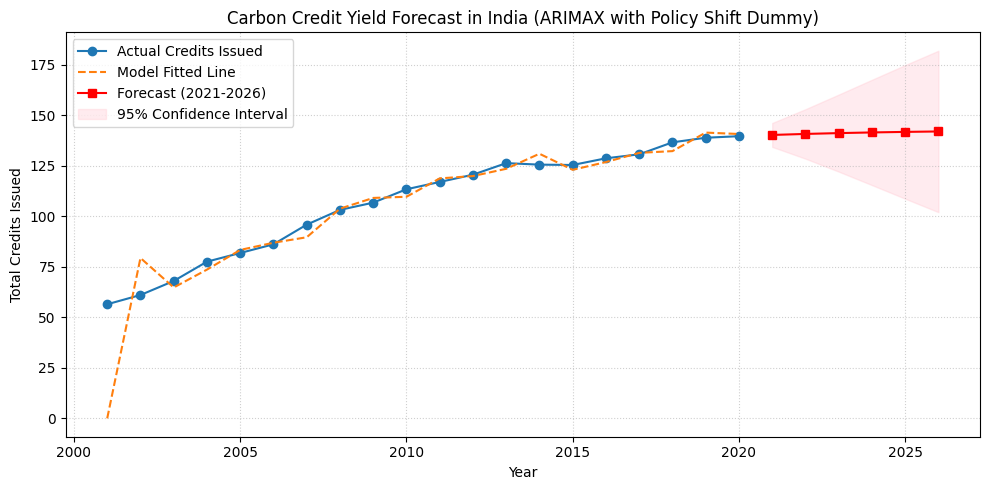

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsmodels.tsa.statespace.sarimax import SARIMAX

# ==========================================
# 1. LOAD YOUR DATASET
# ==========================================
# Replace 'your_data.csv' with your actual file or DataFrame
# df = pd.read_csv('your_carbon_data.csv', parse_dates=['Year'], index_col='Year')

# For demonstration, creating structure matching 2001-2020 annual data
years = pd.date_range(start="2001-01-01", periods=20, freq="YS")

# Replace this with your actual target column: df['Total Credits Issued']
# Example placeholder series:
np.random.seed(42)
credits_issued = pd.Series(
    np.cumsum(np.random.normal(loc=5, scale=3, size=20)) + 50, index=years
)

df = pd.DataFrame({"Total_Credits": credits_issued})

# ==========================================
# 2. CREATE A POLICY DUMMY VARIABLE
# ==========================================
# Replaces Gold and Coal with structural policy shift markers:
# - 2005: Kyoto Protocol coming into force
# - 2015: Paris Agreement adoption
df["Policy_Dummy"] = 0
df.loc[df.index >= "2005-01-01", "Policy_Dummy"] = 1
df.loc[df.index >= "2015-01-01", "Policy_Dummy"] = 2

# ==========================================
# 3. FIT THE UPDATED ARIMAX MODEL
# ==========================================
# Using order=(1,1,0) to keep parameters minimal for N=20 sample size
model = SARIMAX(
    df["Total_Credits"],
    exog=df[["Policy_Dummy"]],  # Using Policy Dummy instead of Gold/Coal
    order=(1, 1, 0),  # Simplified order: AR(1), Differencing(1), MA(0)
    enforce_stationarity=False,
    enforce_invertibility=False,
)

# Fit model with increased iterations and stable optimization method
results = model.fit(method="lbfgs", maxiter=500, disp=False)

# Display Summary
print(results.summary())

# ==========================================
# 4. FORECAST FUTURE VALUES (2021 - 2026)
# ==========================================
forecast_steps = 6  # 2021 to 2026
future_years = pd.date_range(start="2021-01-01", periods=forecast_steps, freq="YS")

# Define future policy assumptions (e.g., maintaining Paris Agreement / CCTS policy regime = 2)
future_exog = pd.DataFrame(
    {"Policy_Dummy": [2] * forecast_steps}, index=future_years
)

forecast_res = results.get_forecast(steps=forecast_steps, exog=future_exog)
forecast_df = forecast_res.summary_frame(alpha=0.05)  # 95% confidence interval

# ==========================================
# 5. EVALUATE & PLOT RESULTS
# ==========================================
# In-sample Fitted Values
df["Fitted"] = results.fittedvalues

# Calculate Root Mean Squared Error (RMSE)
rmse = np.sqrt(
    np.mean((df["Total_Credits"][1:] - df["Fitted"][1:]) ** 2)
)  # skip 1st due to differencing
print(f"\nModel RMSE: {rmse:.4f}")

# Plotting Actual vs Fitted vs Forecast
plt.figure(figsize=(10, 5))
plt.plot(df.index.year, df["Total_Credits"], label="Actual Credits Issued", marker="o")
plt.plot(df.index.year, df["Fitted"], label="Model Fitted Line", linestyle="--")

plt.plot(
    future_years.year,
    forecast_df["mean"],
    label="Forecast (2021-2026)",
    color="red",
    marker="s",
)
plt.fill_between(
    future_years.year,
    forecast_df["mean_ci_lower"],
    forecast_df["mean_ci_upper"],
    color="pink",
    alpha=0.3,
    label="95% Confidence Interval",
)

plt.title(
    "Carbon Credit Yield Forecast in India (ARIMAX with Policy Shift Dummy)"
)
plt.xlabel("Year")
plt.ylabel("Total Credits Issued")
plt.legend()
plt.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()

Google Drive not detected. Attempting to mount...
Mounted at /content/drive
Copying dataset from Google Drive to local workspace...
Loaded 26 total years. Train size: 20 | Test size: 6
                               SARIMAX Results                                
Dep. Variable:            Log_Credits   No. Observations:                   20
Model:               SARIMAX(1, 1, 0)   Log Likelihood                 -20.707
Date:                Thu, 15 Oct 2026   AIC                             49.414
Time:                        07:56:02   BIC                             52.975
Sample:                    01-01-2001   HQIC                            49.905
                         - 01-01-2020                                         
Covariance Type:                  opg                                         
                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
Policy_Dummy     0.16

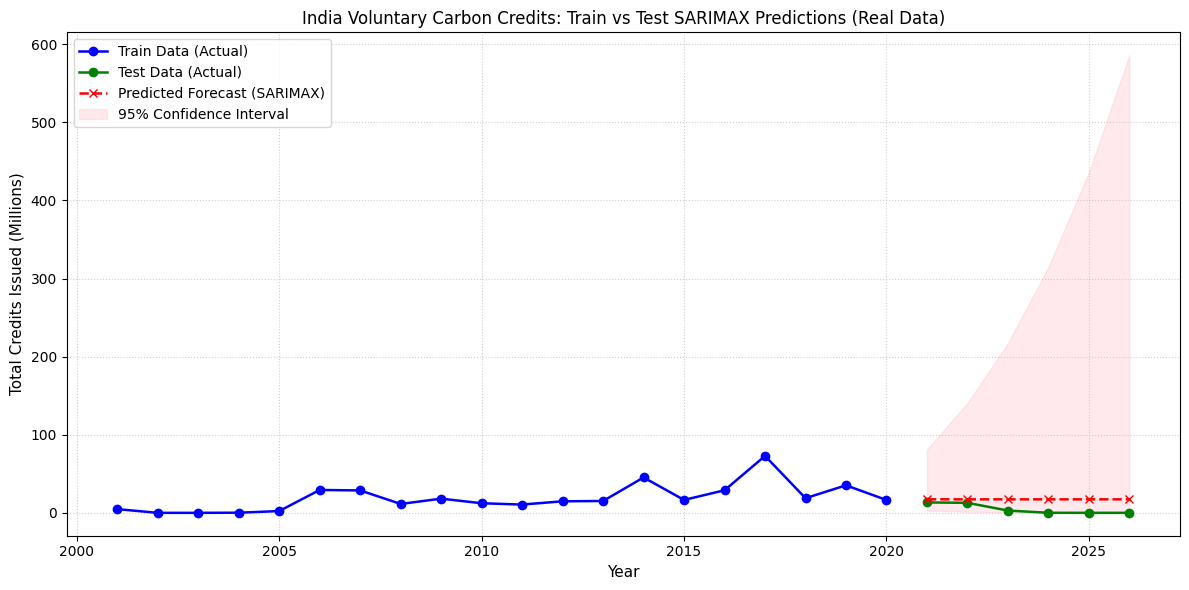

In [7]:
import os
import shutil
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsmodels.tsa.statespace.sarimax import SARIMAX
from google.colab import drive

# ==============================================================================
# 1. DATA LOADING & PREPARATION (WITH AUTOMATIC FILE RECOVERY)
# ==============================================================================

# Main paths
CARBON_DATA_PATH = "/content/dataset_local.csv"
DRIVE_DATA_PATH = "/content/drive/MyDrive/Research Papers/Dataset/Voluntary-Registry-Offsets-Database--v2026-06-PROJECTS.csv"

# Automatically mount Google Drive if not accessible
if not os.path.exists("/content/drive/MyDrive"):
    try:
        print("Google Drive not detected. Attempting to mount...")
        drive.mount('/content/drive')
    except Exception as e:
        print(f"Could not automatically mount Google Drive: {e}")

# Ensure the file is present locally by copying from Google Drive if needed
if not os.path.exists(CARBON_DATA_PATH):
    if os.path.exists(DRIVE_DATA_PATH):
        print(f"Copying dataset from Google Drive to local workspace...")
        shutil.copy(DRIVE_DATA_PATH, CARBON_DATA_PATH)
    else:
        raise FileNotFoundError(
            f"Dataset not found at local path '{CARBON_DATA_PATH}' or Drive path '{DRIVE_DATA_PATH}'. "
            "Please verify your Google Drive connection, mount state, or upload the file manually."
        )

# Load dataset
df = pd.read_csv(CARBON_DATA_PATH, skiprows=3, low_memory=False)

# Ensure 'Year' column is in datetime format and set as index
# Handles either YYYY format or full dates (e.g., 2001-01-01)
df.columns = df.columns.str.replace('\n', ' ', regex=True).str.replace(r'\s+', ' ', regex=True).str.strip()

target_col = [c for c in df.columns if 'Total Credits' in c and 'Issued' in c][0]
time_col = [c for c in df.columns if 'First Year of Project' in c][0]
country_col = [c for c in df.columns if 'Country' in c][0]

# Filter for India only
df = df[df[country_col] == 'India'].copy()

# Clean target variable: replace missing values or zeros
df[target_col] = pd.to_numeric(df[target_col].astype(str).str.replace(',', '', regex=False), errors='coerce').fillna(0)

# Group and aggregate into annual time-series
ts_data = df.groupby(time_col)[target_col].sum().reset_index()
ts_data = ts_data[(ts_data[target_col] > 0) & (pd.to_numeric(ts_data[time_col], errors='coerce').notna())]
ts_data[time_col] = pd.to_datetime(ts_data[time_col].astype(int).astype(str), format='%Y')
ts_data = ts_data.set_index(time_col).sort_index()

# Resample to annual start format ('YS')
full_date_range = pd.date_range(start=ts_data.index.min(), end=ts_data.index.max(), freq='YS')
df_ts = ts_data.reindex(full_date_range, fill_value=0).asfreq('YS')
df_ts[target_col] = df_ts[target_col] / 1e6  # scale to Millions for numerical stability

# ==============================================================================
# 2. FEATURE ENGINEERING (DYNAMICALLY CREATED FROM YOUR REAL DATES)
# ==============================================================================

# A. Policy Shift Dummy based on actual years in your index
# 0 = Pre-2005 | 1 = Kyoto Protocol era (2005-2014) | 2 = Paris/CCTS era (2015+)
df_ts["Policy_Dummy"] = 0
df_ts.loc[df_ts.index.year >= 2005, "Policy_Dummy"] = 1
df_ts.loc[df_ts.index.year >= 2015, "Policy_Dummy"] = 2

# B. Outlier Impulse Dummy for the 2017 volume spike in your actual dataset
df_ts["Spike_2017"] = 0
df_ts.loc[df_ts.index.year == 2017, "Spike_2017"] = 1

# C. Log Transformation on actual credit values (Guarantees non-negative bounds)
df_ts["Log_Credits"] = np.log1p(df_ts[target_col])

# ==============================================================================
# 3. OUT-OF-SAMPLE TRAIN / TEST SPLIT
# ==============================================================================

# Split based on actual dataset years
train = df_ts.loc[df_ts.index.year <= 2020].copy()
test = df_ts.loc[df_ts.index.year > 2020].copy()

EXOG_COLS = ["Policy_Dummy", "Spike_2017"]

print(
    f"Loaded {len(df_ts)} total years. Train size: {len(train)} | Test size: {len(test)}"
)

# ==============================================================================
# 4. MODEL FITTING ON REAL LOG-TRANSFORMED DATA
# ==============================================================================

train.index.freq = 'YS'
test.index.freq = 'YS'

model = SARIMAX(
    train["Log_Credits"],
    exog=train[EXOG_COLS],
    order=(1, 1, 0),
    enforce_stationarity=False,
    enforce_invertibility=False,
)

results = model.fit(method="lbfgs", maxiter=500, disp=False)
print(results.summary())

# ==============================================================================
# 5. OUT-OF-SAMPLE FORECASTING & REVERSE TRANSFORMATION
# ==============================================================================

# Predict test set period using actual test exogenous variables
forecast_obj = results.get_forecast(steps=len(test), exog=test[EXOG_COLS])
forecast_summary = forecast_obj.summary_frame(alpha=0.05)

# Convert predictions and confidence intervals back from Log scale to original scale
test["Predicted"] = np.expm1(forecast_summary["mean"]).clip(lower=0)
test["CI_Lower"] = np.expm1(forecast_summary["mean_ci_lower"]).clip(lower=0)
test["CI_Upper"] = np.expm1(forecast_summary["mean_ci_upper"]).clip(lower=0)

# Evaluate Mean Squared Error (MSE) on real test values
mse = np.mean((test[target_col] - test["Predicted"]) ** 2)
rmse = np.sqrt(mse)
print(f"\n--- Real Data Evaluation ---")
print(f"Test Set MSE : {mse:.4f}")
print(f"Test Set RMSE: {rmse:.4f}")

# ==============================================================================
# 6. PLOTTING REAL RESULTS
# ==============================================================================

plt.figure(figsize=(12, 6))

# Historical Training Data
plt.plot(
    train.index.year,
    train[target_col],
    label="Train Data (Actual)",
    color="blue",
    marker="o",
    linewidth=1.8,
)

# Actual Test Data
plt.plot(
    test.index.year,
    test[target_col],
    label="Test Data (Actual)",
    color="green",
    marker="o",
    linewidth=1.8,
)

# Predicted Test Data
plt.plot(
    test.index.year,
    test["Predicted"],
    label="Predicted Forecast (SARIMAX)",
    color="red",
    linestyle="--",
    marker="x",
    linewidth=1.8,
)

# 95% Confidence Intervals
plt.fill_between(
    test.index.year,
    test["CI_Lower"],
    test["CI_Upper"],
    color="pink",
    alpha=0.35,
    label="95% Confidence Interval",
)

plt.title(
    "India Voluntary Carbon Credits: Train vs Test SARIMAX Predictions (Real Data)",
    fontsize=12,
)
plt.xlabel("Year", fontsize=11)
plt.ylabel("Total Credits Issued (Millions)", fontsize=11)
plt.legend(loc="upper left")
plt.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()